# MiniGPT from scratch: Colab runner

This notebook reproduces the whole project from a clean checkout:
tests → architecture evidence → training → generation → evaluation → attention maps → ablations → API.

**Runtime → Change runtime type → T4 GPU** before running. The full pipeline takes about 30–40 minutes on a T4.

## 1. Clone and install

In [1]:
!unzip -q -o /content/transformer-gpt-assignment.zip -d /content
%cd /content/transformer-gpt-assignment
!pip install -q -r requirements.txt

/content/transformer-gpt-assignment


In [2]:
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

torch 2.11.0+cu130 | CUDA: True | Tesla T4


## 2. Unit tests and the tiny overfit gate

In [3]:
!python -m pytest -q

.................................                                        [100%]


In [4]:
!python -m src.train --overfit

overfit step    0 | loss 4.1957
overfit step   50 | loss 0.1792
overfit step  100 | loss 0.0061
overfit step  150 | loss 0.0032
overfit step  200 | loss 0.0022
overfit step  250 | loss 0.0016
initial loss 4.1957 (log V = 4.1744) -> final 0.0013


## 3. Architecture evidence (Figures 1–5)

In [5]:
!python -m experiments.attention_numeric_example
!python -m experiments.shape_trace
!python -m experiments.positional_encoding_viz


Q:
  [  1.0000,   0.0000]
  [  0.0000,   1.0000]
  [  1.0000,   1.0000]

K:
  [  1.0000,   0.0000]
  [  0.0000,   1.0000]
  [  1.0000,   1.0000]

V:
  [  1.0000,   2.0000]
  [  3.0000,   4.0000]
  [  5.0000,   6.0000]

1) Q K^T:
  [  1.0000,   0.0000,   1.0000]
  [  0.0000,   1.0000,   1.0000]
  [  1.0000,   1.0000,   2.0000]

2) Q K^T / sqrt(d_k)   (sqrt(2) = 1.4142):
  [  0.7071,   0.0000,   0.7071]
  [  0.0000,   0.7071,   0.7071]
  [  0.7071,   0.7071,   1.4142]

3) softmax (row-wise)  -> each row sums to 1:
  [  0.4011,   0.1978,   0.4011]
  [  0.1978,   0.4011,   0.4011]
  [  0.2483,   0.2483,   0.5035]

4) output = weights @ V:
  [  3.0000,   4.0000]
  [  3.4067,   4.4067]
  [  3.5105,   4.5105]

================ with causal mask ================

causal mask (1 = allowed, 0 = future/blocked):
  [  1.0000,   0.0000,   0.0000]
  [  1.0000,   1.0000,   0.0000]
  [  1.0000,   1.0000,   1.0000]

5) masked scores:
  [  0.7071,     -inf,     -inf]
  [  0.0000,   0.7071,     -inf]
  [

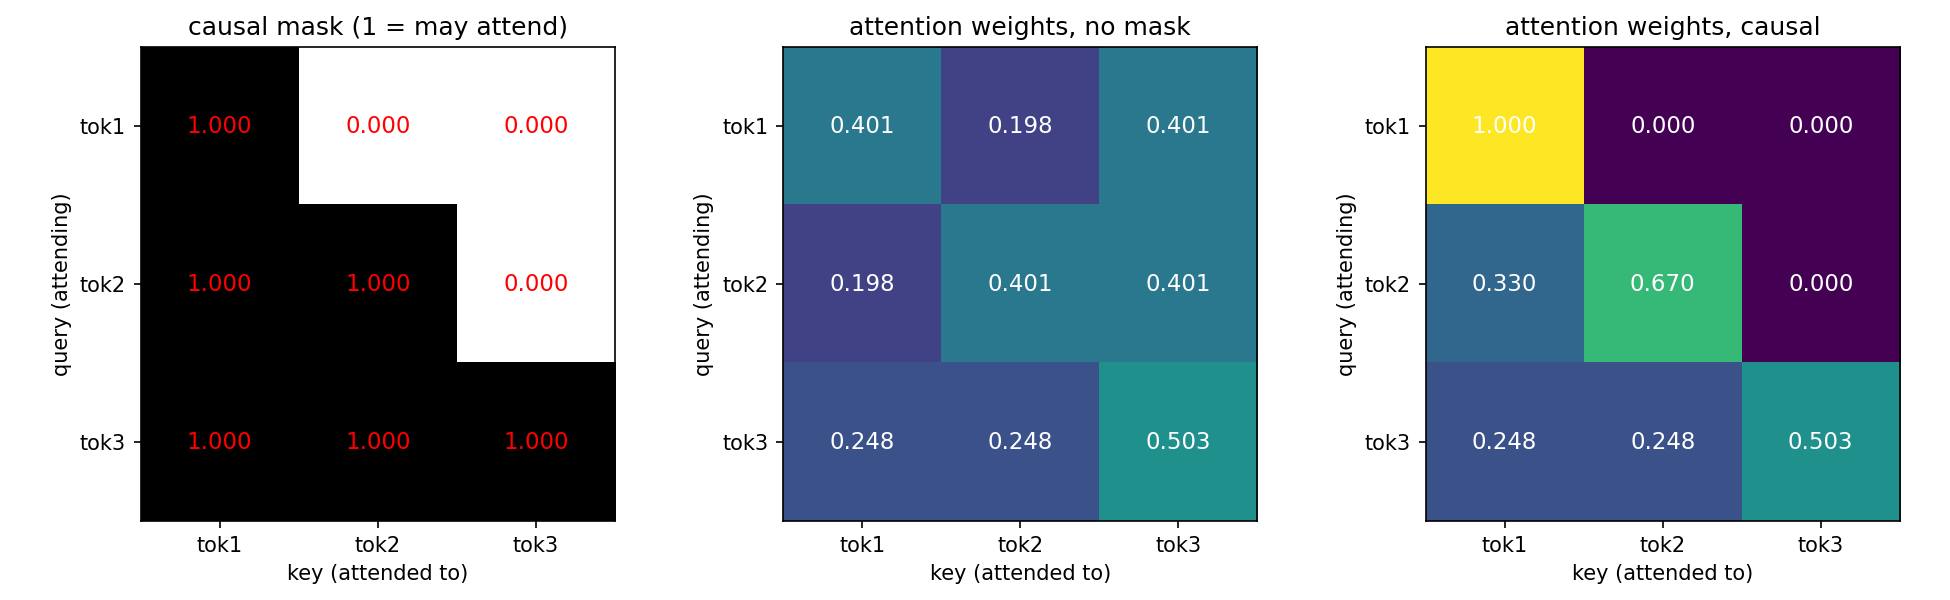

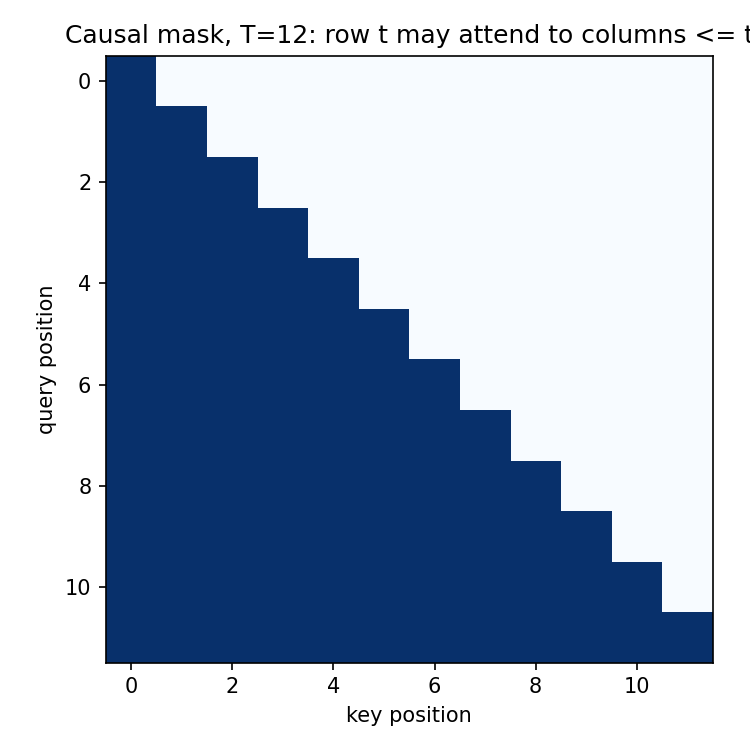

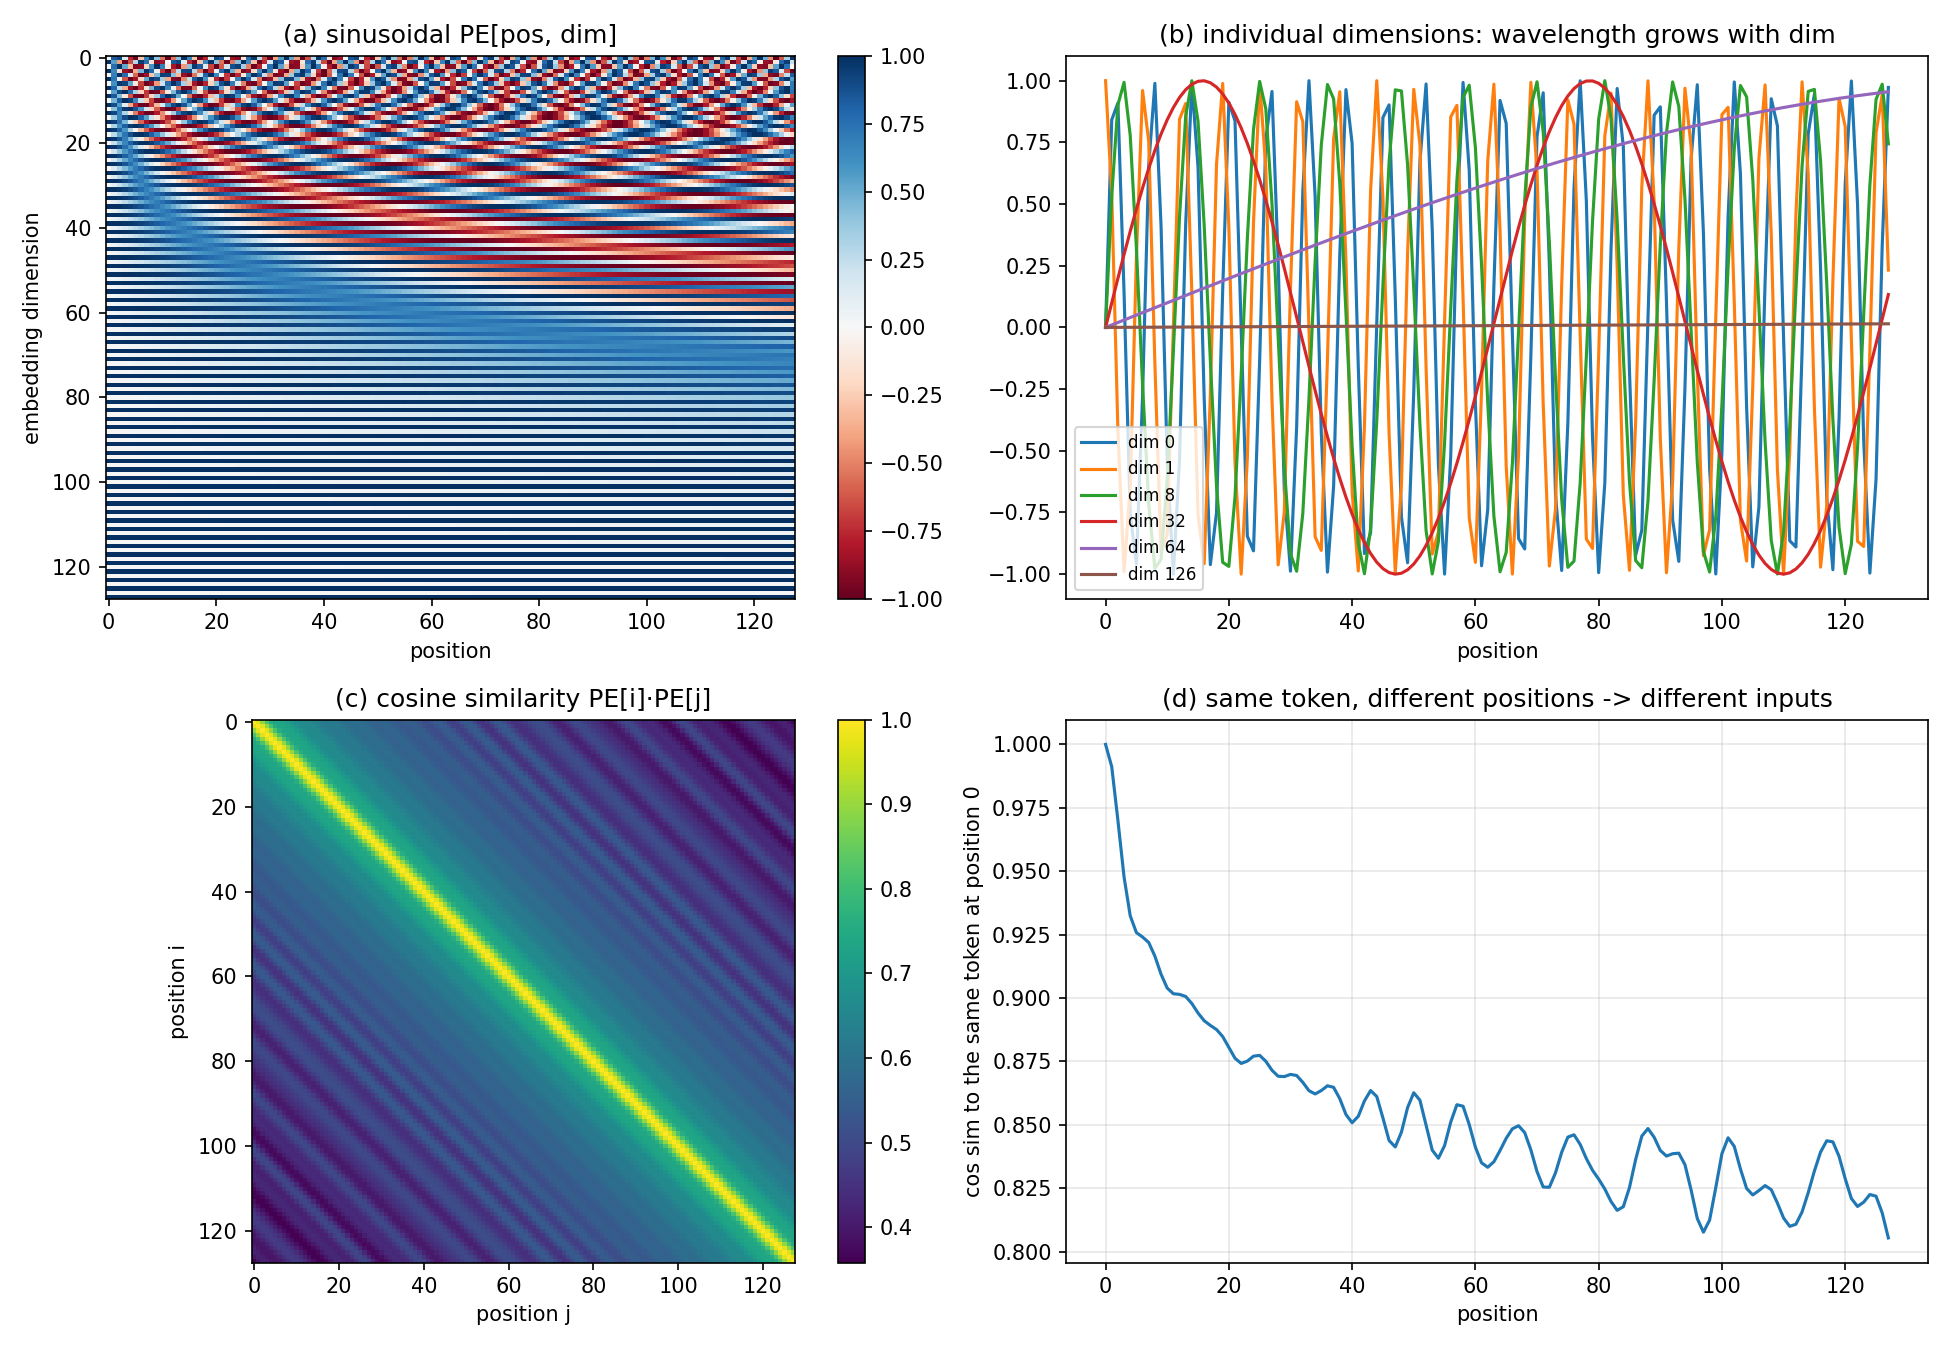

In [6]:
from IPython.display import Image, display
for f in ["fig2_causal_mask_3tok.png", "fig2_causal_mask_12.png", "fig4_positional_encoding.png"]:
    display(Image(f"outputs/figures/{f}"))

### Lesson 01: RNN vs self-attention timing (on the GPU) and Lesson 06: MLM vs CLM

T=16 | rnn_loop_ms=1.36 | rnn_fused_ms=0.26 | attention_ms=0.61 | rnn_sequential_steps=16 | attention_sequential_steps=1 | attention_scores_MB=0.06 | rnn_hidden_states_MB=0.12
T=32 | rnn_loop_ms=3.56 | rnn_fused_ms=0.23 | attention_ms=0.60 | rnn_sequential_steps=32 | attention_sequential_steps=1 | attention_scores_MB=0.25 | rnn_hidden_states_MB=0.25
T=64 | rnn_loop_ms=6.76 | rnn_fused_ms=0.23 | attention_ms=0.55 | rnn_sequential_steps=64 | attention_sequential_steps=1 | attention_scores_MB=1.00 | rnn_hidden_states_MB=0.50
T=128 | rnn_loop_ms=12.60 | rnn_fused_ms=0.32 | attention_ms=0.68 | rnn_sequential_steps=128 | attention_sequential_steps=1 | attention_scores_MB=4.00 | rnn_hidden_states_MB=1.00
T=256 | rnn_loop_ms=29.15 | rnn_fused_ms=0.55 | attention_ms=1.51 | rnn_sequential_steps=256 | attention_sequential_steps=1 | attention_scores_MB=16.00 | rnn_hidden_states_MB=2.00
T=512 | rnn_loop_ms=51.10 | rnn_fused_ms=1.01 | attention_ms=4.62 | rnn_sequential_steps=512 | attention_sequenti

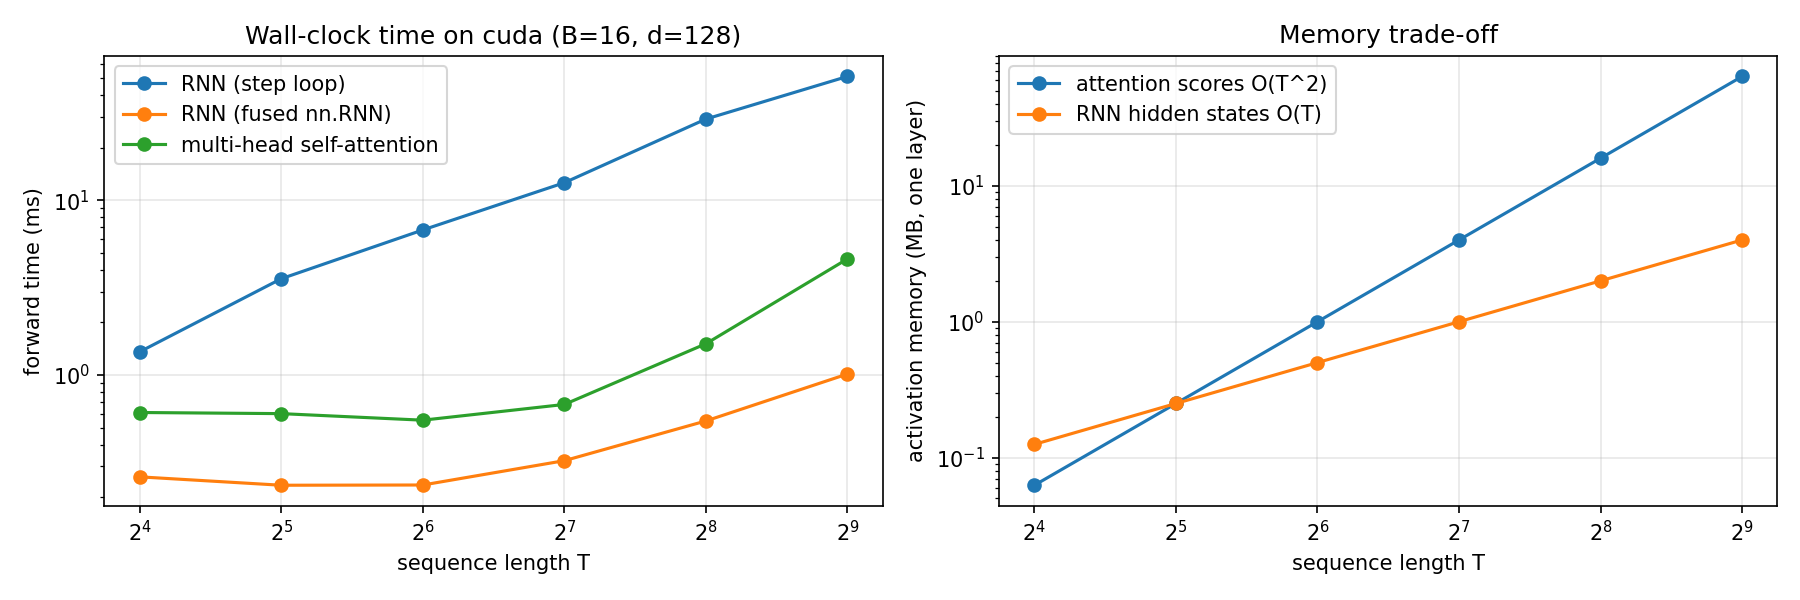

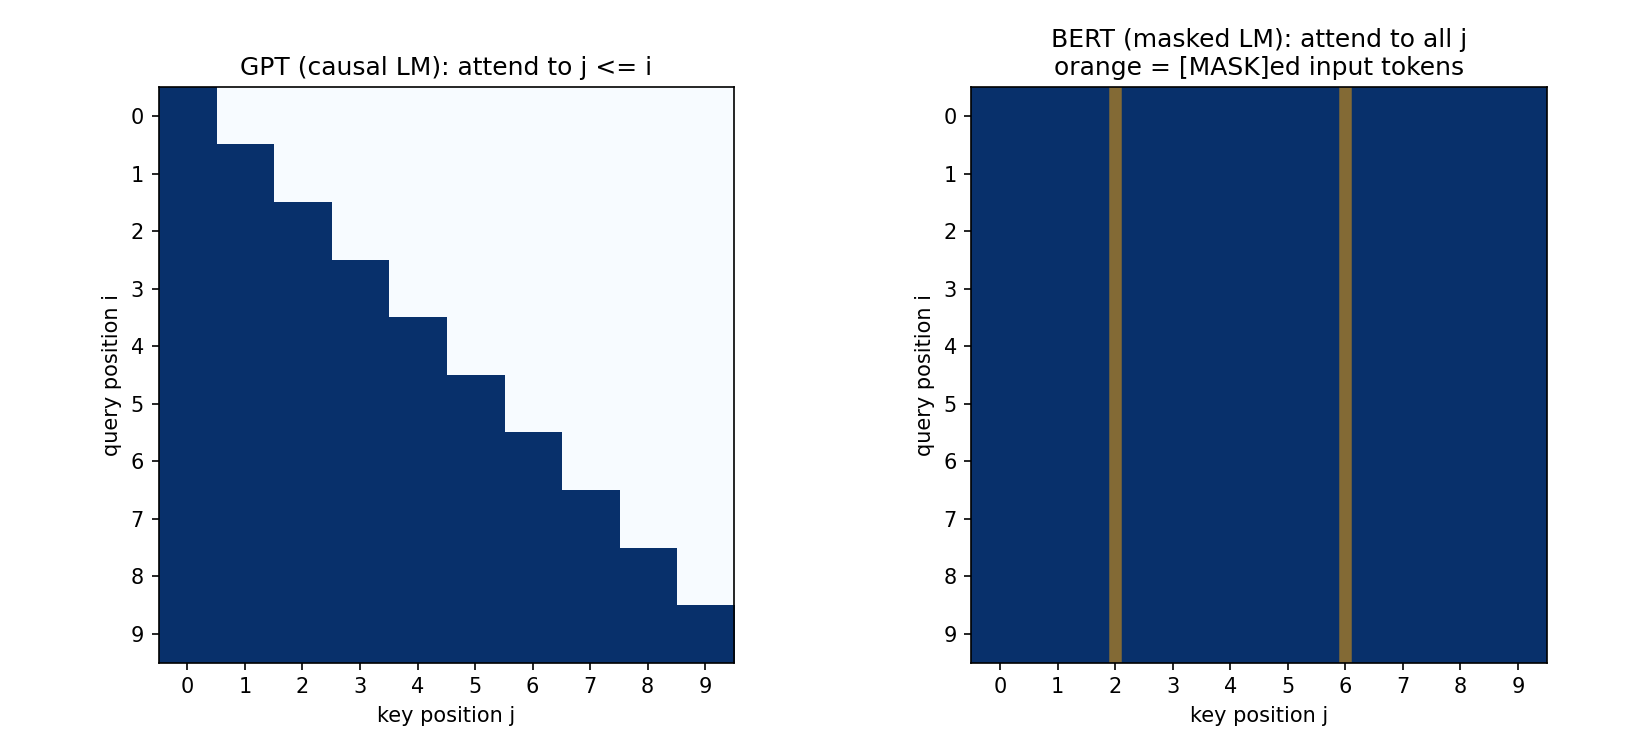

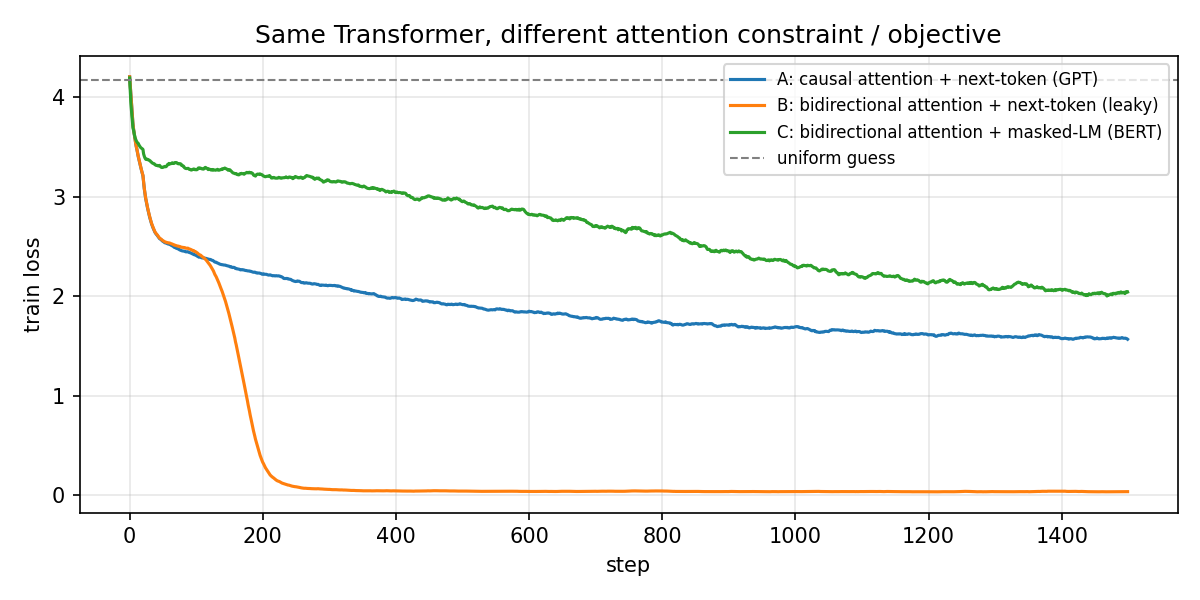

In [7]:
!python -m experiments.why_transformers
!python -m experiments.mask_comparison --steps 1500
for f in ["why_transformers.png", "fig_mlm_vs_clm_masks.png", "fig_mlm_vs_clm_losses.png"]:
    display(Image(f"outputs/figures/{f}"))

## 4. Train the baseline MiniGPT (Figures 5, 6, 8)

Configuration: `configs/tiny_gpt.yaml`. Any value can be overridden with `--set section.key=value`.

*Skip this cell* if you only want to run inference with a published checkpoint (see section 9).

In [8]:
!python -m src.train

device: Tesla T4
vocab_size: 65 | train tokens: 1,003,854 | val tokens: 111,540
model parameters: 809,984 (810.0K)
config: GPTConfig(vocab_size=65, context_length=128, d_model=128, n_heads=4, n_layers=4, ffn_dim=512, dropout=0.1, pos_encoding='sinusoidal', tie_weights=False, causal=True)
step     0 | lr 3.00e-05 | train 4.2185 | val 4.2185 (ppl 67.93) | 0 tok/s | 0s
step   250 | lr 2.99e-03 | train 2.2773 | val 2.2263 (ppl 9.27) | 235,545 tok/s | 5s
step   500 | lr 2.96e-03 | train 1.9307 | val 1.9639 (ppl 7.13) | 231,256 tok/s | 9s
step   750 | lr 2.88e-03 | train 1.7504 | val 1.8241 (ppl 6.20) | 248,364 tok/s | 14s
step  1000 | lr 2.78e-03 | train 1.6576 | val 1.7356 (ppl 5.67) | 243,628 tok/s | 18s
--- sample @ step 1000 ---
ROMEO:
I am I not like moine buy thy mocking.

NORTHUMBERLAND:
Why was duke in the fathed! it unto grace,
To faith me shall burn the gran true a pleace
Of sover fear, goest for the from heideld.

SICINIUS:

---
step  1250 | lr 2.65e-03 | train 1.6015 | val 1.703

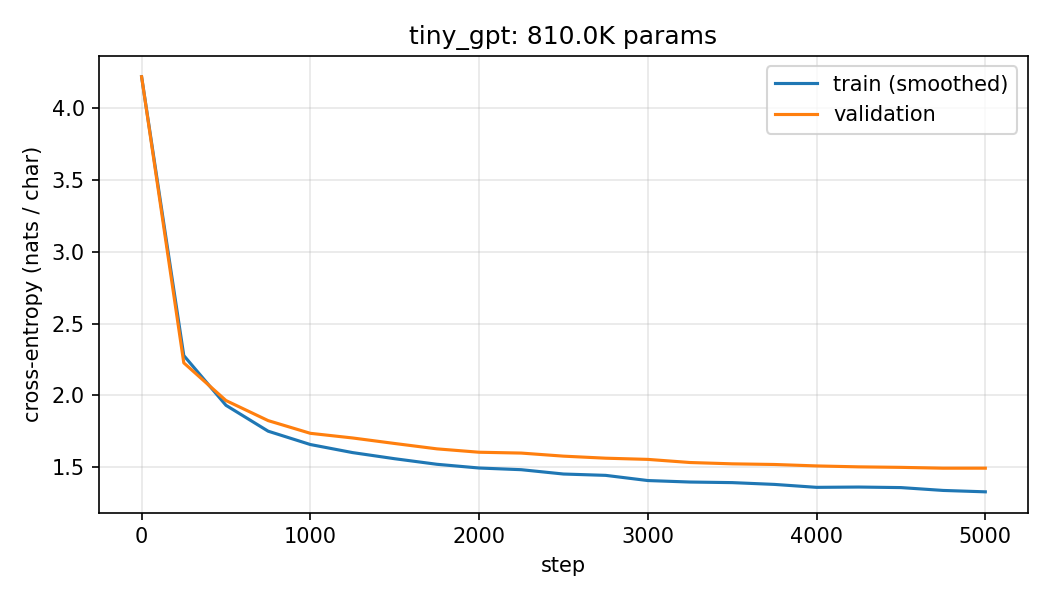

{
  "run_name": "tiny_gpt",
  "parameters": 809984,
  "model_config": {
    "vocab_size": 65,
    "context_length": 128,
    "d_model": 128,
    "n_heads": 4,
    "n_layers": 4,
    "ffn_dim": 512,
    "dropout": 0.1,
    "pos_encoding": "sinusoidal",
    "tie_weights": false,
    "causal": true
  },
  "train_config": {
    "seed": 1337,
    "device": "auto",
    "batch_size": 32,
    "max_steps": 5000,
    "optimizer": "adamw",
    "lr": 0.003,
    "min_lr": 0.0003,
    "warmup_steps": 100,
    "weight_decay": 0.1,
    "betas": [
      0.9,
      0.99
    ],
    "grad_clip": 1.0,
    "eval_interval": 250,
    "eval_batches": 20,
    "sample_interval": 1000,
    "sample_prompt": "ROMEO:",
    "sample_tokens": 200,
    "temperature": 0.8,
    "out_dir": "checkpoints",
    "run_name": "tiny_gpt"
  },
  "hardware": "Tesla T4",
  "train_time_sec": 94.6,
  "step_time_sec": 87.6,
  "tokens_per_sec": 233852.0,
  "peak_memory_mb": 249.1,
  "final_train_loss": 1.2609,
  "final_val_loss": 1.4929

In [9]:
import json
display(Image("outputs/figures/tiny_gpt_loss.png"))
print(json.dumps(json.load(open("outputs/logs/tiny_gpt_summary.json")), indent=2))

## 5. Generation from fixed prompts (CLI)

In [10]:
!python -m src.generate --prompt "ROMEO:" --max-new-tokens 300 --seed 0
!python -m src.generate --prompt "JULIET:" --max-new-tokens 300 --seed 0
!python -m src.generate --prompt "To be, or not to be" --max-new-tokens 300 --temperature 0

Prompt: ROMEO:
Generated: ROMEO:
Say this earth? Hoise! shall I have have been
For not give my hour friends, for I shall be
To say the faithful shall be commplor there's disease.
If your servant Naunt, and the partise of the flies
Unso the each of wrongs cannot seem for love.

ESCALUS:
Let her breath he me to thy most demand
Have 

model parameters: 810.0K (809,984)
layers/heads/d_model: 4/4/128 | vocab: 65
context length: 128
temperature: 0.8 | top_k: None | top_p: None | seed: 0
checkpoint: /content/transformer-gpt-assignment/checkpoints/tiny_gpt.pt (step 4750, val loss 1.4928)
device: cuda
Prompt: JULIET:
Generated: JULIET:
I am I not like more of you.

DUKE OF AUMERLE:
And we have my life in the provided with your brother,
Which he shall be come to any remedy.

QUEEN MARGARET:
Then Norfolk, the drum that but be in the day,
Sudden by your prevails do it.

CLARENCE:
I was not be ever worful boy, or poor man.
Romeo, tha

model parameters: 810.0K (809,984)
layers/heads/d_model: 4/4/128

## 6. Evaluation: full validation perplexity, 5 fixed prompts, decoding comparison

In [11]:
!python -m experiments.evaluate
from IPython.display import Markdown
display(Markdown(open("outputs/samples/evaluation.md").read()))

{
  "checkpoint": "/content/transformer-gpt-assignment/checkpoints/tiny_gpt.pt",
  "parameters": 809984,
  "val_loss": 1.4933,
  "val_perplexity": 4.452,
  "val_bits_per_char": 2.1544,
  "uniform_baseline_loss": 4.1744
}

===== prompt 1: 'ROMEO:' =====
ROMEO:
As look and that I make him down that noble
And they fear her place of quite, and that's then?
As it well, if uncertain famous meaning not like
colder by a present drunk and the fair both.

POMPEY:
I shall say you not a patrician on a wuld
They have done the appear secret.

DUKE OF YORK:
Not all be

===== prompt 2: 'JULIET:\nO Romeo,' =====
JULIET:
O Romeo, what is the loss of thine own conjure?

CLARENCE:
My lord, do I see, prepare you for this man.

Nurse:
O perform'd is this street with your wretch,
The valiant is my lord: shall sets him herein
As my others rively of our such ause,
If hangs from his accused the meating close.

CAMILLO:
Thou art for

===== prompt 3: 'KING HENRY:\nWhat news' =====
KING HENRY:
What news ling only 

# Evaluation

```json
{
  "checkpoint": "/content/transformer-gpt-assignment/checkpoints/tiny_gpt.pt",
  "parameters": 809984,
  "val_loss": 1.4933,
  "val_perplexity": 4.452,
  "val_bits_per_char": 2.1544,
  "uniform_baseline_loss": 4.1744
}
```

## Fixed-prompt samples (temperature 0.8, seed 42, 300 new chars)

### Prompt 1: `'ROMEO:'`

```
ROMEO:
As look and that I make him down that noble
And they fear her place of quite, and that's then?
As it well, if uncertain famous meaning not like
colder by a present drunk and the fair both.

POMPEY:
I shall say you not a patrician on a wuld
They have done the appear secret.

DUKE OF YORK:
Not all be
```

### Prompt 2: `'JULIET:\nO Romeo,'`

```
JULIET:
O Romeo, what is the loss of thine own conjure?

CLARENCE:
My lord, do I see, prepare you for this man.

Nurse:
O perform'd is this street with your wretch,
The valiant is my lord: shall sets him herein
As my others rively of our such ause,
If hangs from his accused the meating close.

CAMILLO:
Thou art for
```

### Prompt 3: `'KING HENRY:\nWhat news'`

```
KING HENRY:
What news ling only that invocase thee?

BENVOLIO:
Who shall think you do come?

MISTRESS OVERDONE:
The projure I can not be put hunged.

First Musician:
Sirrah, nor I say, there the oaths house my lord:
If my husband, sir, that I am I not the Lady,
And that I may play her send them shall shall all tell me
H
```

### Prompt 4: `'First Citizen:\n'`

```
First Citizen:
We think the desire of so much make me my son,
That I think the subjects thou very well.
What thou wilt I see with all great call thy delivers?

ISABELLA:
The country live and remember all.

CLARENCE:
Better the prince send?

VIRGILIA:
Before the truth; my lord, I pray the liege,
Seem them him bears
```

### Prompt 5: `'To be, or not to be'`

```
To be, or not to be the prince.

SICINIUS:
Is that he proclaim'd more crown: why, is't the glock,
Whereon our soldiers best kiss than thou shouldst
All be her.

HENRY BOLINGBROKE:
I must not have straight design to the deed.

PLINCESTER:
Ay, now my lords, I would not care him friend
That I to tell thee, on a very rest
```

## Decoding strategy comparison (prompt `ROMEO:`)

| strategy | distinct words | distinct bigrams | repeated char 4-grams | real-word fraction |
|---|---|---|---|---|
| greedy (T=0) | 0.216 | 0.309 | 0.726 | 1.0 |
| T=0.5 | 0.69 | 0.99 | 0.199 | 0.98 |
| T=0.8 | 0.765 | 1.0 | 0.123 | 0.951 |
| T=1.0 | 0.765 | 0.99 | 0.115 | 0.929 |
| T=1.5 | 0.94 | 1.0 | 0.046 | 0.747 |
| T=0.8, top-k=10 | 0.77 | 1.0 | 0.133 | 0.95 |

**greedy (T=0)**

```
ROMEO:
I will not so so much a straight of the court.

LEONTES:
What is the country?

CORIOLANUS:
I will not see the prince of the country's son,
That I will be so much a straight of the sea
That the state of the seat of the seat of the sea
That the state of the state of the state of the sea
That the state of the state of the state of the sea
That the state of the state of the state of the sea
Tha
```

**T=0.5**

```
ROMEO:
I can lose thee, and there shall be a necked for thee.

PETRUCHIO:
Why, the crown that stands thee,
That would have seen to the deed hands and make him
That change he did should be stand upon his forth.

GLOUCESTER:
Then I have not the under that I did speak a sword;
The common of your brother soul, and do you say
The seen and his good friends, in his honour.

KING RICHARD III:
Go, come, fo
```

**T=0.8**

```
ROMEO:
As look and that I make him down that noble
And they fear her place of quite, and that's then?
As it well, if uncertain famous meaning not like
colder by a present drunk and the fair both.

POMPEY:
I shall say you not a patrician on a wuld
They have done the appear secret.

DUKE OF YORK:
Not all better than visit 'name I have shown.

ANTIGONUS:
So, then shall I should be both out of the day
```

**T=1.0**

```
ROMEO:
As look and for your great sun.

SICINIUS:
A fellow eyes are deliver
To dream a weeping king, from the particiu
In sigh fame, cheering noble leads, a woman's fool.

FLORIZEL:
They but not not say, but men so it not usurpose;
Now, like turn a rent mercy from a great
Meanest that consuls, when alsomething do we
were not of the pass poor clease of mother;
Or bidems that I prove to-none the day
```

**T=1.5**

```
ROMEO:
Kind Lord, days, and not the neath, annd Lodowe thought
Was go lamp'd cqure of kintnal's planly spirit.

WARWICK:
Weigh fame!--
Son, 'tis trulh, thy temp and foolish prevain,
They but not night a, but Welvesditize husband;
His heaviol'd, dark,
My more fattheral were couvertors; consuls, Thus?

LEONTES:
Come, faith's deserve! O, by to queen,
Wofuls, too hopest, Keep
Mrings o-hope, Froth.
do,
```

**T=0.8, top-k=10**

```
ROMEO:
As I have stay'd the matter'd with all,
And the words of thee that true the crown
And have bring our world.

Provost:
The mercy of the contral of his house are son?

LUCIO:
He had but not cheer and do well say 'Think your honour,
You have been it shall be my consent in this brother.

Second Senator:
No, no more comes born to be.

First Lord:
The strong hours and heart
Were the wood, the did
```


## 7. Attention maps from the trained model (Figure 7)

prompt (57 chars): 'ROMEO:\nBut soft, what light through yonder window breaks?'

layer head | mean look-back distance | weight on previous char | weight on self
    0    0 |                    3.13 |                   0.124 |          0.054
    0    1 |                    0.94 |                   0.931 |          0.079
    0    2 |                    1.78 |                   0.580 |          0.156
    0    3 |                    2.12 |                   0.383 |          0.078
    1    0 |                    2.61 |                   0.414 |          0.118
    1    1 |                    3.52 |                   0.325 |          0.120
    1    2 |                    3.79 |                   0.183 |          0.140
    1    3 |                    2.80 |                   0.241 |          0.097
    2    0 |                    3.07 |                   0.432 |          0.085
    2    1 |                   17.27 |                   0.040 |          0.041
    2    2 |                    2.86 | 

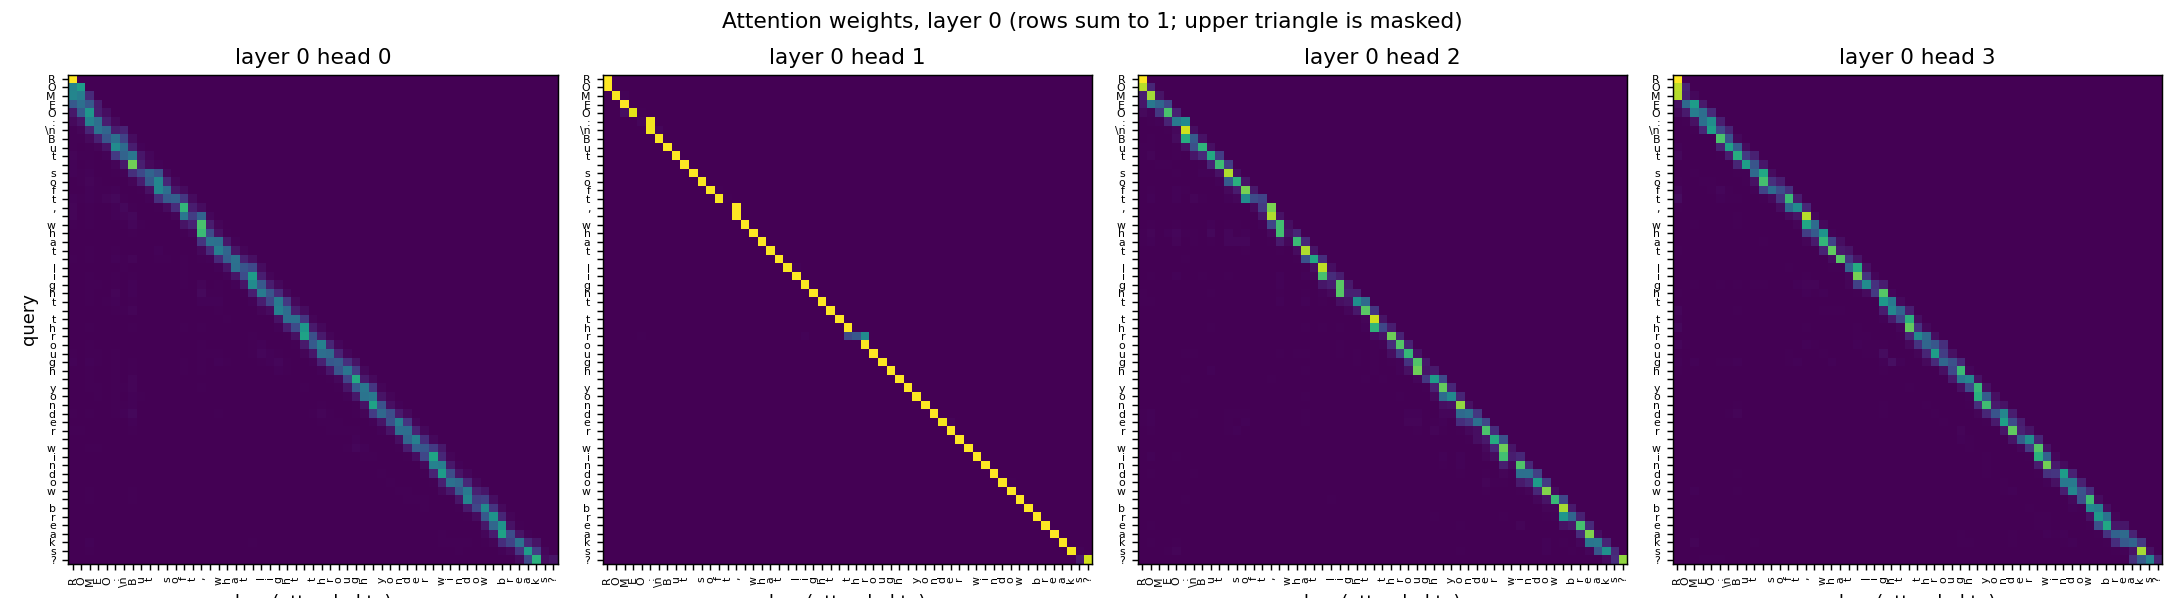

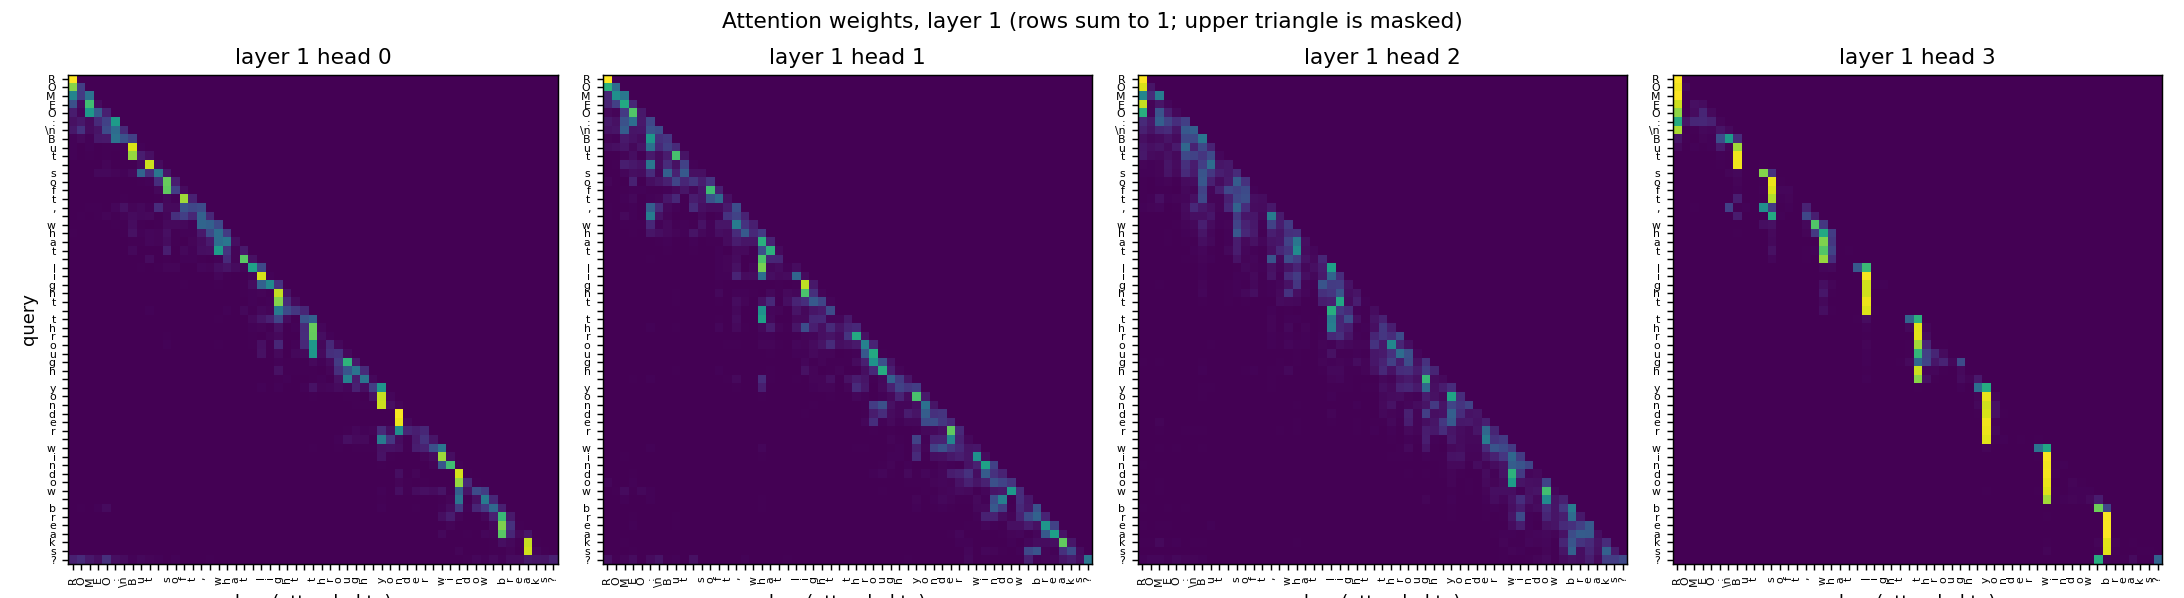

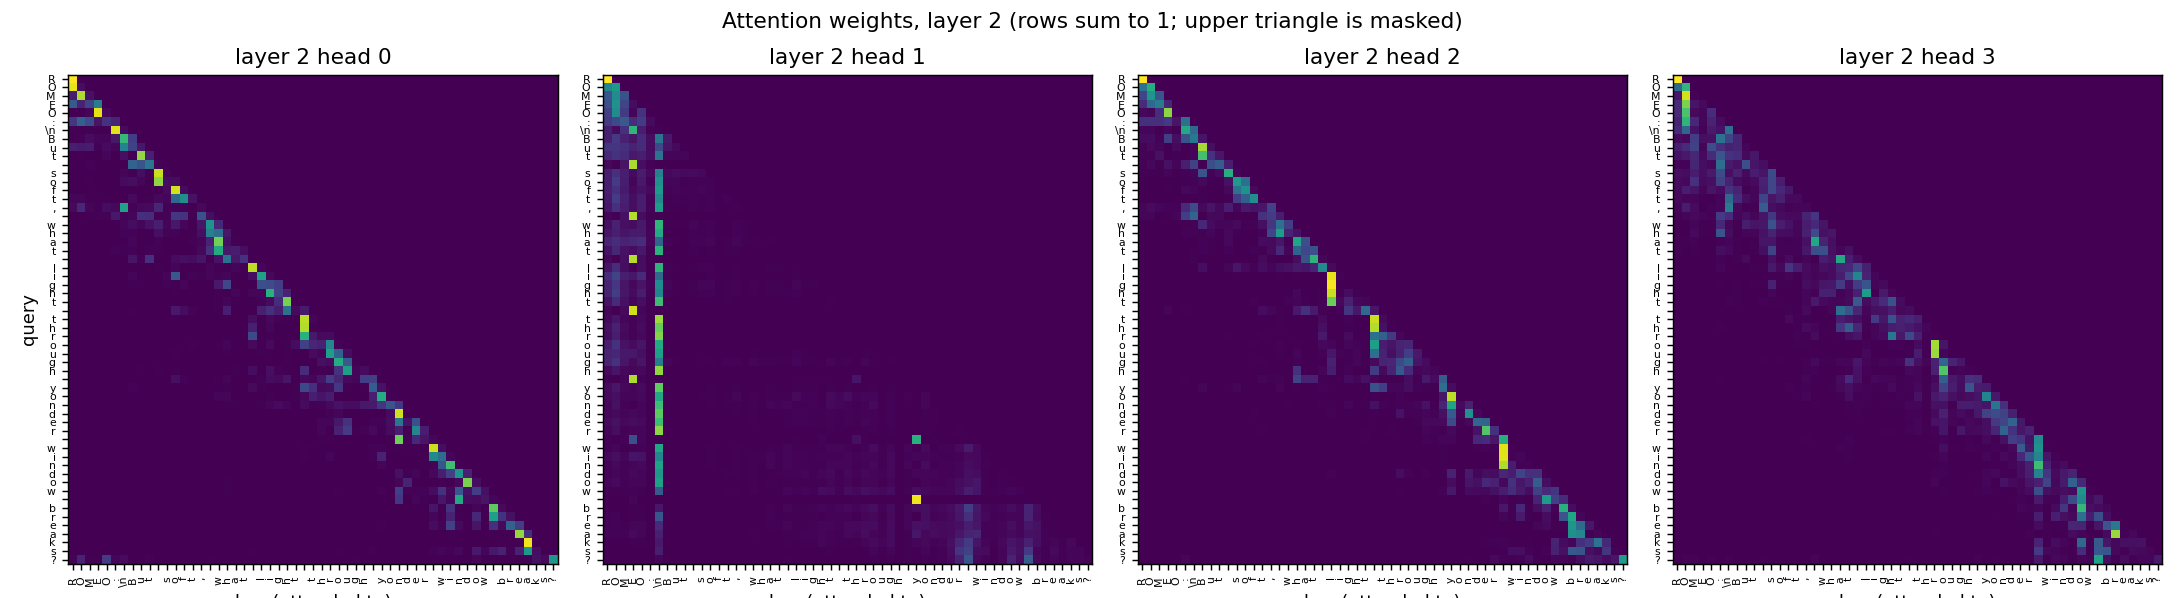

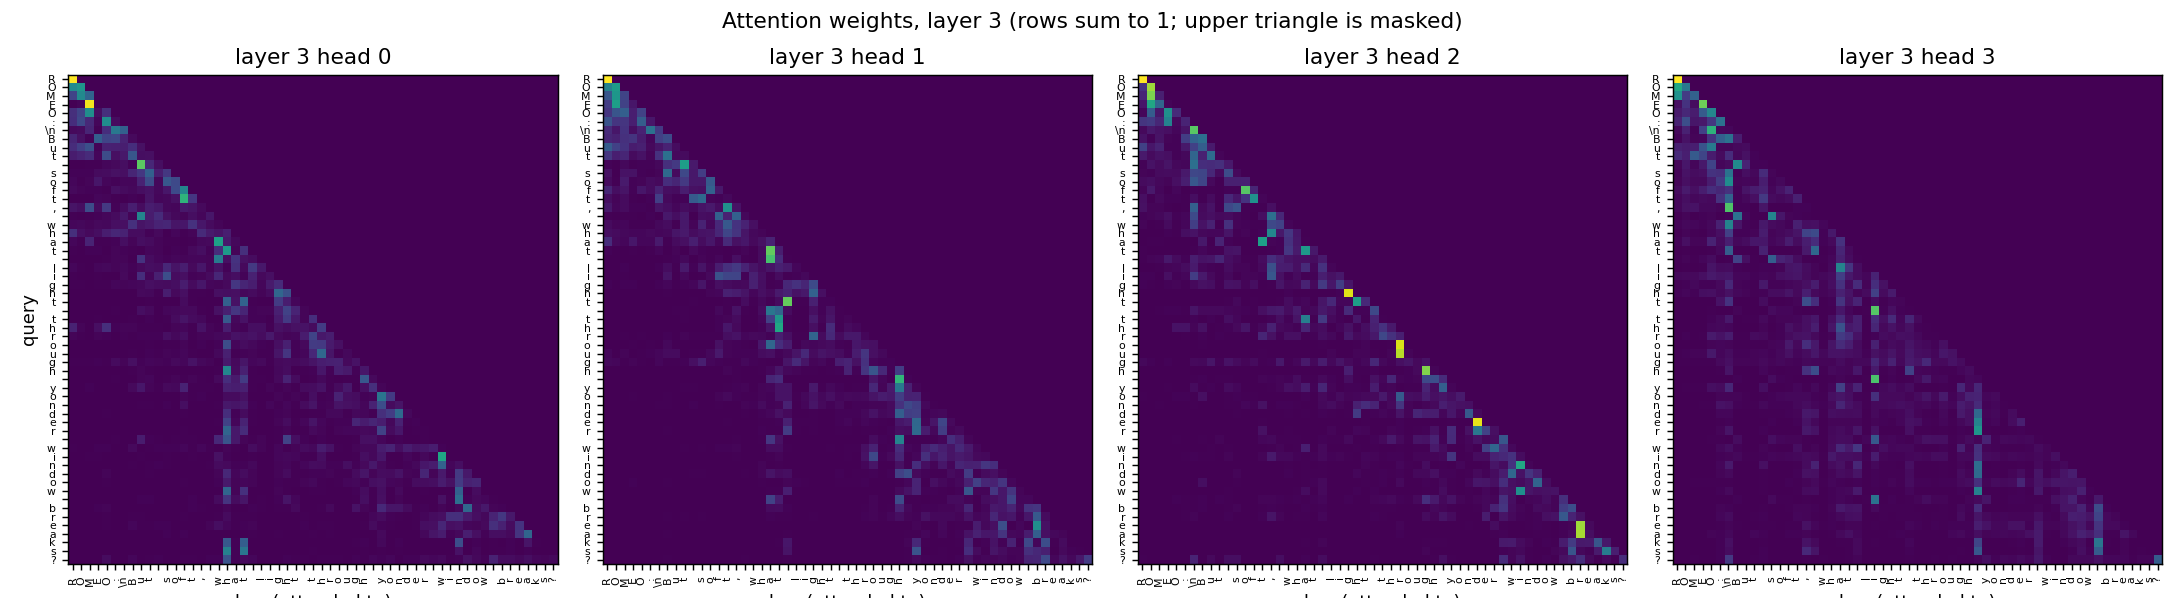

In [12]:
!python -m experiments.attention_visualization
import glob
for f in sorted(glob.glob("outputs/figures/fig7_attention_layer*.png")):
    display(Image(f))

## 8. Ablations (Figure 9)

Depth (2/4/6 layers), heads (2/4/8), context length (64/128/256), each 2000 steps with everything else fixed.
Add `position` to the list for the optional sinusoidal vs learned vs none study.


######## depth = 2 ########
{'study': 'depth', 'value': 2, 'parameters': 413440, 'final_train_loss': 1.4902, 'final_val_loss': 1.6841, 'best_val_loss': 1.6841, 'val_ppl': 5.388, 'train_time_sec': 19.7, 'step_time_sec': 18.2, 'tokens_per_sec': 449100.4, 'peak_gpu_memory_mb': 142.4, 'attention_matrix_mb': None}

######## depth = 4 ########
{'study': 'depth', 'value': 4, 'parameters': 809984, 'final_train_loss': 1.3984, 'final_val_loss': 1.6036, 'best_val_loss': 1.6036, 'val_ppl': 4.971, 'train_time_sec': 37.7, 'step_time_sec': 35.5, 'tokens_per_sec': 230463.3, 'peak_gpu_memory_mb': 249.1, 'attention_matrix_mb': None}

######## depth = 6 ########
{'study': 'depth', 'value': 6, 'parameters': 1206528, 'final_train_loss': 1.3703, 'final_val_loss': 1.5693, 'best_val_loss': 1.5693, 'val_ppl': 4.803, 'train_time_sec': 54.7, 'step_time_sec': 51.6, 'tokens_per_sec': 158713.8, 'peak_gpu_memory_mb': 355.8, 'attention_matrix_mb': None}

######## heads = 2 ########
{'study': 'heads', 'value': 2, 'pa

| study | value | parameters | final_train_loss | final_val_loss | best_val_loss | val_ppl | train_time_sec | step_time_sec | tokens_per_sec | peak_gpu_memory_mb | attention_matrix_mb |
|---|---|---|---|---|---|---|---|---|---|---|---|
| depth | 2 | 413440 | 1.4902 | 1.6841 | 1.6841 | 5.388 | 19.7 | 18.2 | 449100.4 | 142.4 |  |
| depth | 4 | 809984 | 1.3984 | 1.6036 | 1.6036 | 4.971 | 37.7 | 35.5 | 230463.3 | 249.1 |  |
| depth | 6 | 1206528 | 1.3703 | 1.5693 | 1.5693 | 4.803 | 54.7 | 51.6 | 158713.8 | 355.8 |  |
| heads | 2 | 809984 | 1.4126 | 1.6131 | 1.6131 | 5.018 | 32.9 | 30.8 | 266068.4 | 213.1 |  |
| heads | 4 | 809984 | 1.3984 | 1.6036 | 1.6036 | 4.971 | 37.3 | 35.0 | 234135.9 | 249.1 |  |
| heads | 8 | 809984 | 1.4081 | 1.61 | 1.61 | 5.003 | 46.4 | 43.9 | 186661.2 | 321.1 |  |
| context | 64 | 809984 | 1.4932 | 1.6642 | 1.6642 | 5.282 | 28.5 | 27.0 | 151586.6 | 119.5 | 8.0 |
| context | 128 | 809984 | 1.3984 | 1.6036 | 1.6036 | 4.971 | 37.0 | 34.9 | 234681.7 | 249.1 | 32.0 |
| context | 256 | 809984 | 1.3441 | 1.5632 | 1.5632 | 4.774 | 89.6 | 86.5 | 189446.4 | 613.8 | 128.0 |

## Samples (prompt `ROMEO:`, temperature 0.8, seed 0)

**depth = 2**

```
ROMEO:
Say thing all at time but in they well;
Now in me not good my lord with the father!

BRUTUS:
You look Waith me shear but stops a there's dise,
In I should swear teak and bellow there had
Be to like w

```

**depth = 4**

```
ROMEO:
Say thinks a man! if God up you come,
For it well not good my lord of your battled!

Nurse:
Yes, look this the shall be common a treath.

SICINIUS:
Now, I swear this state the purge dil war
Which you

```

**depth = 6**

```
ROMEO:
Say things, bear time by us you call death?

FRIAR LAURENCE:
This controus battle so sounds grace, thou it the shall be
come to limps and in a garling sinces away.

BUCKINGHAM:
And is law and in seal

```

**heads = 2**

```
ROMEO:
Say thinks, be thou art you well time.

Nurse:
And we have my lord:
And the father! it unto gracelo, if it the shall be?
Why shall the said with of sovereign a gone.

MARCIUS:
Such is law the is seal

```

**heads = 4**

```
ROMEO:
Say thinks a man! if God up you come,
For it well not good my lord of your battled!

Nurse:
Yes, look this the shall be common a treath.

SICINIUS:
Now, I swear this state the purge dil war
Which you

```

**heads = 8**

```
ROMEO:
I am I not liege! if God, the mocks his wall be eye;
And by with us the lady had dead our sound.

GRUMIO:
Sir, sir; he commons and the makes a garlieves,
Tessave the state to drumplishly.

LUCIO:
Now

```

**context = 64**

```
ROMEO:
Say things an Clifice but thy mocking.

Nurse:
And love's such thrue in the father! is unto grace,
This impind she of thyself.

RIVERS:
Lord a garlieve in the wound land.

STOP OF
First Margan:
And w

```

**context = 128**

```
ROMEO:
Say thinks a man! if God up you come,
For it well not good my lord of your battled!

Nurse:
Yes, look this the shall be common a treath.

SICINIUS:
Now, I swear this state the purge dil war
Which you

```

**context = 256**

```
ROMEO:
Say he no general in his bidd me?

ABHORSON:
Fellow no fortune. Could your father souls,
The brant to Warwick the Cousin Warwick there's disertain.

FRIAR LAURENCE:
But and the partience.

SICINIUS:


```


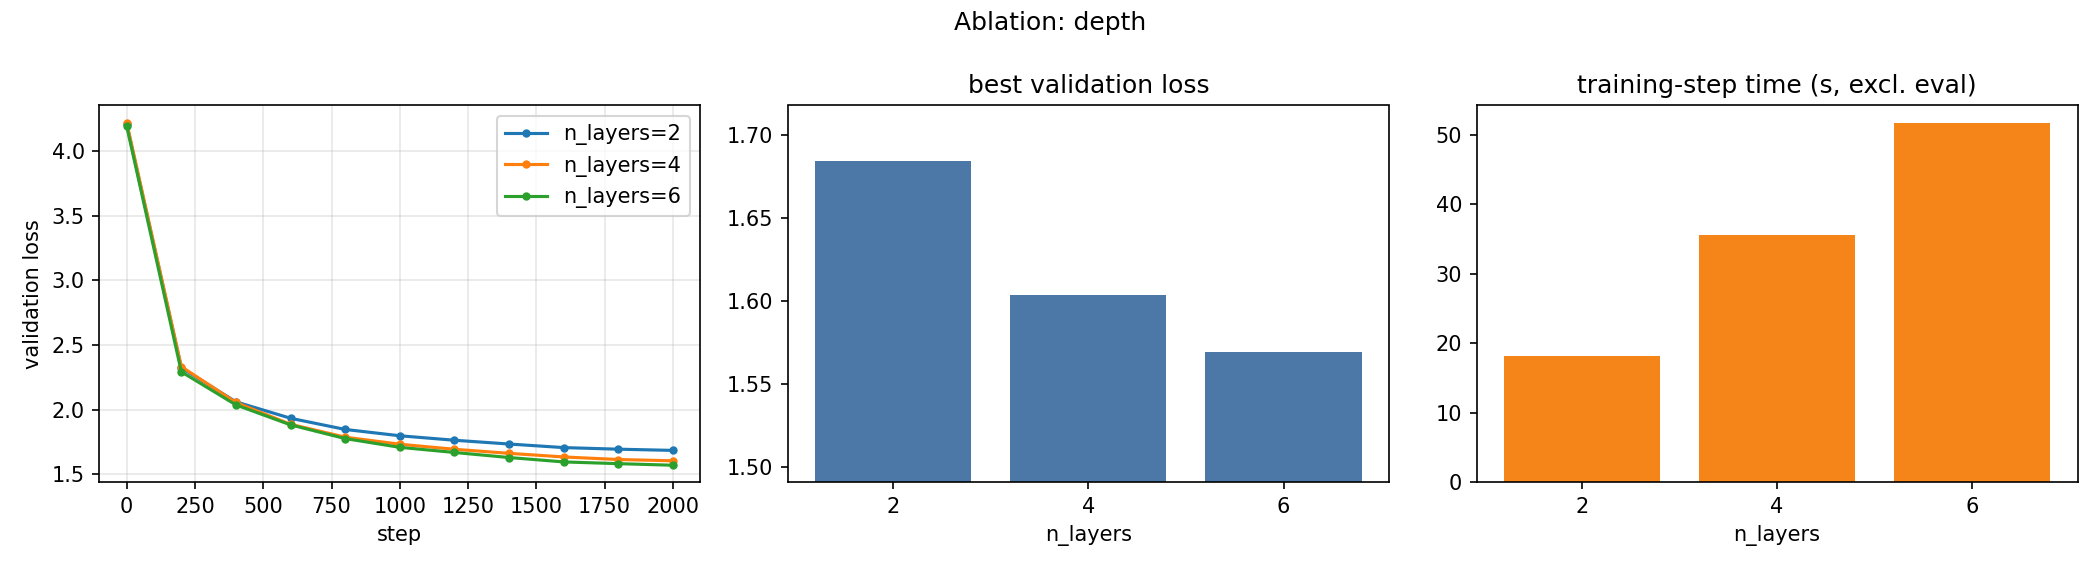

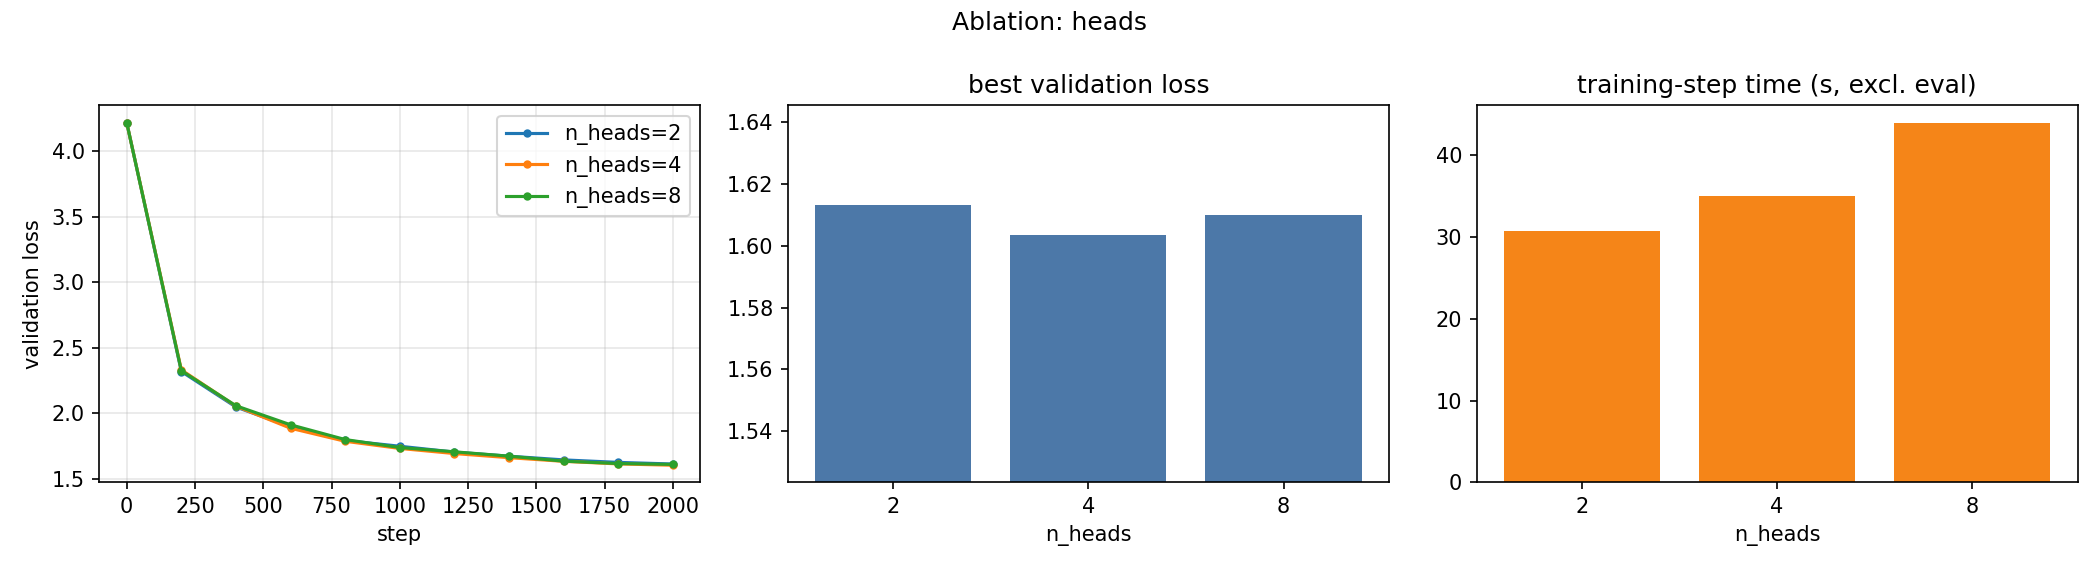

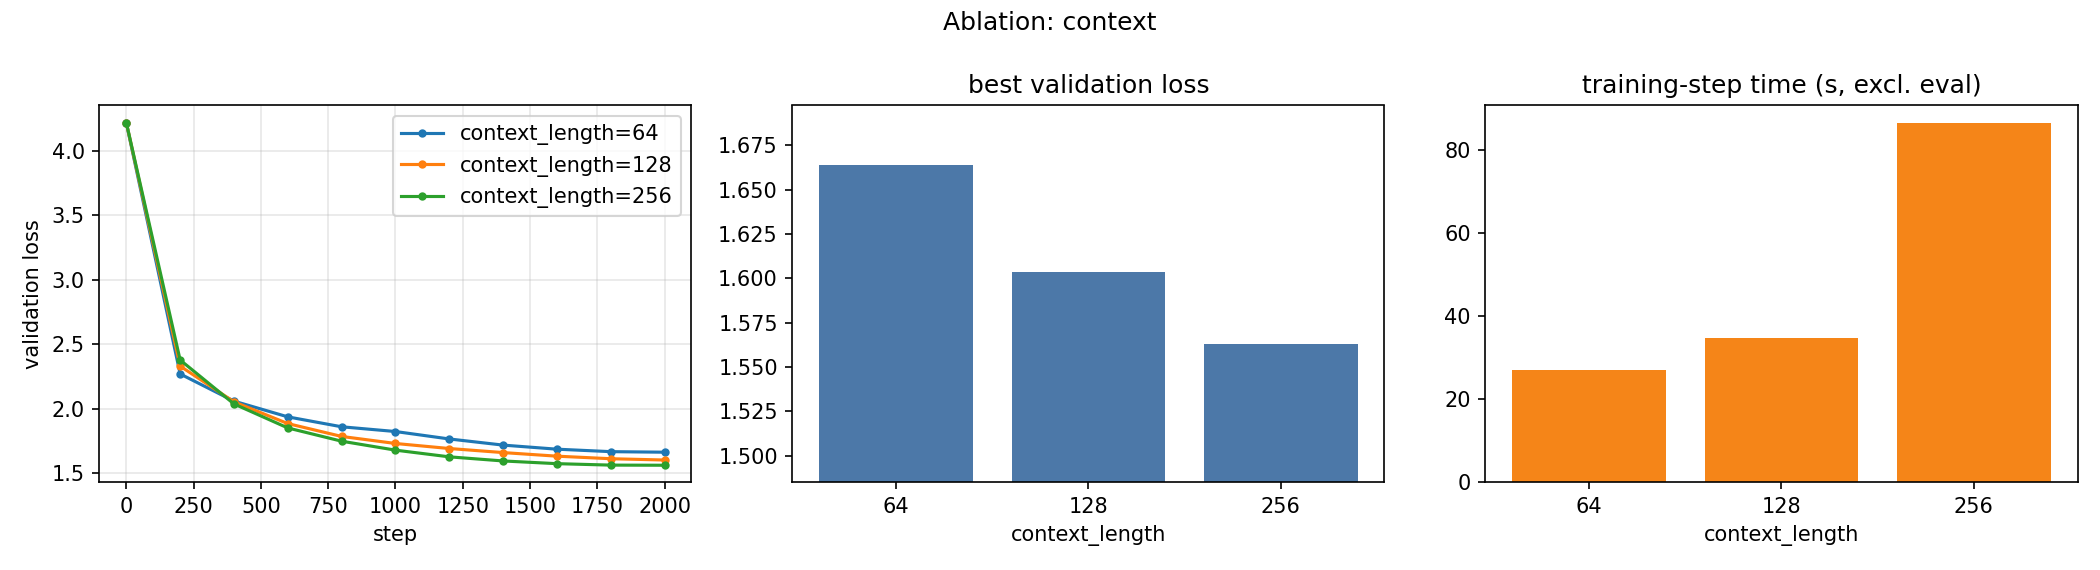

In [13]:
!python -m experiments.ablation --studies depth heads context --steps 2000
display(Markdown(open("outputs/ablation/ablation_results.md").read()))
for s in ["depth", "heads", "context"]:
    display(Image(f"outputs/ablation/ablation_{s}.png"))

In [14]:
# optional
!python -m experiments.ablation --studies position --steps 2000


######## position = sinusoidal ########
{'study': 'position', 'value': 'sinusoidal', 'parameters': 809984, 'final_train_loss': 1.3984, 'final_val_loss': 1.6036, 'best_val_loss': 1.6036, 'val_ppl': 4.971, 'train_time_sec': 37.8, 'step_time_sec': 35.4, 'tokens_per_sec': 231678.5, 'peak_gpu_memory_mb': 249.1, 'attention_matrix_mb': None}

######## position = learned ########
{'study': 'position', 'value': 'learned', 'parameters': 826368, 'final_train_loss': 1.4961, 'final_val_loss': 1.6884, 'best_val_loss': 1.6884, 'val_ppl': 5.411, 'train_time_sec': 37.3, 'step_time_sec': 35.1, 'tokens_per_sec': 233331.1, 'peak_gpu_memory_mb': 249.2, 'attention_matrix_mb': None}

######## position = none ########
{'study': 'position', 'value': 'none', 'parameters': 809984, 'final_train_loss': 1.6463, 'final_val_loss': 1.816, 'best_val_loss': 1.816, 'val_ppl': 6.147, 'train_time_sec': 37.2, 'step_time_sec': 34.9, 'tokens_per_sec': 234438.4, 'peak_gpu_memory_mb': 249.1, 'attention_matrix_mb': None}

wrote

## 9. Inference-only path: load a published checkpoint

If the checkpoint is not in the repo, set `CHECKPOINT_URL` to a GitHub release asset or a public Google Drive
share link; `src.utils.load_checkpoint` downloads it on first use.

In [15]:
# os.environ["CHECKPOINT_URL"] = "https://drive.google.com/file/d/<FILE_ID>/view?usp=sharing"
!python -m src.generate --checkpoint checkpoints/tiny_gpt.pt --prompt "ROMEO:" --seed 1

Prompt: ROMEO:
Generated: ROMEO:
If yet my heart is uncle.

MENENIUS:
Stay, the gods of his complain to knave
A wife and next that I never be like breath,
As there sweety to the end, sir, we will be false
There in happy pleased hast

model parameters: 810.0K (809,984)
layers/heads/d_model: 4/4/128 | vocab: 65
context length: 128
temperature: 0.8 | top_k: None | top_p: None | seed: 1
checkpoint: checkpoints/tiny_gpt.pt (step 4750, val loss 1.4928)
device: cuda


## 10. REST API inside Colab

In [16]:
import subprocess, time, requests
server = subprocess.Popen(["uvicorn", "api.app:app", "--port", "8000"])
time.sleep(8)
print(requests.get("http://127.0.0.1:8000/health").json())
r = requests.post("http://127.0.0.1:8000/generate",
                  json={"prompt": "ROMEO:", "max_new_tokens": 200, "temperature": 0.8, "seed": 0})
print(r.json()["generated_text"])
server.terminate()

{'status': 'ok', 'model_loaded': True}
ROMEO:
The more king solemnly can expect,
And gels them come with the bear change of sleep
To save him stands, your ways and comes are,
Make not the soon of Pompey.

Second Murderer:
Scannot she would be va


## 11. Save the results

In [17]:
!zip -qr results.zip outputs checkpoints/tiny_gpt.pt
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>